# Inventory Demand Forecasting — Data Exploration

In this notebook, we explore the M5 retail sales data before building forecasting models.

We will check the data, understand how often sales are zero, and look for patterns across dates and weekdays.

## 1. Import the libraries

- `pandas` helps us work with data tables.
- `numpy` helps with numerical calculations.
- `matplotlib` creates charts.
- `Path` helps Python find our project files.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

## 2. Find the project folders

We start from the current folder and move up until we find `Datasets`. This lets the notebook locate the data even if VS Code starts it from a subfolder.

In [2]:
PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "Datasets").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "Datasets" / "raw"
FIGURE_DIR = PROJECT_ROOT / "report" / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)
print("Raw data folder exists:", RAW_DIR.exists())

Project folder: /Users/palwaitejaswini/Inventory-demand-forecasting
Raw data folder exists: True


## 3. Load the three data files

We use three files:
- **Sales:** daily sales history for each product-store series.
- **Calendar:** dates, weekdays, events, and SNAP indicators.
- **Prices:** weekly selling prices for items at stores.

We parse the calendar's `date` column as dates so we can group and plot by time.

In [3]:
sales = pd.read_csv(RAW_DIR / "sales_train_validation.csv")

calendar = pd.read_csv(
    RAW_DIR / "calendar.csv",
    parse_dates=["date"]
)

# Category and smaller numeric dtypes reduce memory use for this 194 MB file.
prices = pd.read_csv(
    RAW_DIR / "sell_prices.csv",
    dtype={
        "store_id": "category",
        "item_id": "category",
        "wm_yr_wk": "int32",
        "sell_price": "float32"
    }
)

print("Sales shape:", sales.shape)
print("Calendar shape:", calendar.shape)
print("Prices shape:", prices.shape)

Sales shape: (30490, 1919)
Calendar shape: (1969, 14)
Prices shape: (6841121, 4)


## 4. Identify the daily sales columns

The sales table contains identifier columns plus daily columns named `d_1`, `d_2`, and so on. We collect those daily column names into one list.

In [4]:
sales_cols = [
    column for column in sales.columns
    if column.startswith("d_") and column[2:].isdigit()
]

print("Number of sales days:", len(sales_cols))
print("First sales column:", sales_cols[0])
print("Last sales column:", sales_cols[-1])

Number of sales days: 1913
First sales column: d_1
Last sales column: d_1913


## 5. Preview the sales data

Each row represents one product-store series. The `d_` columns show how many units were sold on each day.

In [5]:
display(sales.head())

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,3,0,1,1,1,3,0,1,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,2,1,1,1,0,1,1,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,5,4,1,0,1,3,7,2
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,1,0,1,1,2,2,2,4


## 6. Check the sizes of the files

The row and column counts tell us how large each dataset is before we begin analysis.

In [6]:
sizes = pd.DataFrame({
    "dataset": ["sales", "calendar", "prices"],
    "rows": [len(sales), len(calendar), len(prices)],
    "columns": [sales.shape[1], calendar.shape[1], prices.shape[1]]
})

display(sizes)

,dataset,rows,columns
0,sales,30490,1919
1,calendar,1969,14
2,prices,6841121,4


## 7. Check for duplicate rows

Duplicate rows can cause the same observation to be counted more than once. We check complete-row duplicates in each file.

In [7]:
duplicates = pd.DataFrame({
    "dataset": ["sales", "calendar", "prices"],
    "duplicate rows": [
        sales.duplicated().sum(),
        calendar.duplicated().sum(),
        prices.duplicated().sum()
    ]
})

display(duplicates)

,dataset,duplicate rows
0,sales,0
1,calendar,0
2,prices,0


## 8. Check important identifiers

Each sales series should have a unique ID, each calendar day should appear once, and each item-store-week combination should have one price record.

In [8]:
print("Duplicate sales IDs:", sales["id"].duplicated().sum())
print("Duplicate calendar day IDs:", calendar["d"].duplicated().sum())

duplicate_price_keys = prices.duplicated(
    ["store_id", "item_id", "wm_yr_wk"]
).sum()

print("Duplicate item-store-week price keys:", duplicate_price_keys)

Duplicate sales IDs: 0
Duplicate calendar day IDs: 0


Duplicate item-store-week price keys: 0


## 9. Check missing values

Missing event names in the calendar can simply mean that no named event was scheduled. We check missing values in all three files so we know where they occur.

In [9]:
missing_values = pd.DataFrame({
    "dataset": ["sales", "calendar", "prices"],
    "missing values": [
        sales.isna().sum().sum(),
        calendar.isna().sum().sum(),
        prices.isna().sum().sum()
    ]
})

display(missing_values)

,dataset,missing values
0,sales,0
1,calendar,7542
2,prices,0


## 10. Check that the calendar dates are continuous

The calendar should move forward one day at a time. We also check that every sales-day column has a matching calendar entry.

In [10]:
calendar = calendar.sort_values("date").reset_index(drop=True)

date_gaps = (
    calendar["date"].diff().dropna() != pd.Timedelta(days=1)
).sum()

missing_calendar_days = len(set(sales_cols) - set(calendar["d"]))

print("Gaps in calendar dates:", int(date_gaps))
print("Sales columns without a calendar match:", missing_calendar_days)

Gaps in calendar dates: 0
Sales columns without a calendar match: 0


## 11. Select the daily sales values

The daily sales columns contain the actual demand values. We keep them together so we can calculate summary statistics and plot their distribution.

In [11]:
daily_sales = sales[sales_cols]

print("Number of daily sales observations:", daily_sales.size)

Number of daily sales observations: 58327370


## 12. Calculate basic demand statistics

We calculate the mean, median, maximum, and percentage of observations that are zero. The median helps show what a typical observation looks like when many values are small or zero.

In [12]:
zero_share = (daily_sales.to_numpy() == 0).mean()

demand_summary = pd.Series({
    "Total observations": daily_sales.size,
    "Mean sales": daily_sales.to_numpy().mean(),
    "Median sales": np.median(daily_sales.to_numpy()),
    "Maximum sales": daily_sales.to_numpy().max(),
    "Zero sales (%)": zero_share * 100
})

display(demand_summary.to_frame("value").round(2))

,value
Total observations,58327370.00
Mean sales,1.13
Median sales,0.00
Maximum sales,763.00
Zero sales (%),68.20


## 13. Plot the demand distribution

This histogram shows how often different sales quantities occur. We limit the chart to values up to the 99.5th percentile so a small number of very large values do not dominate the plot. The underlying data are not changed.

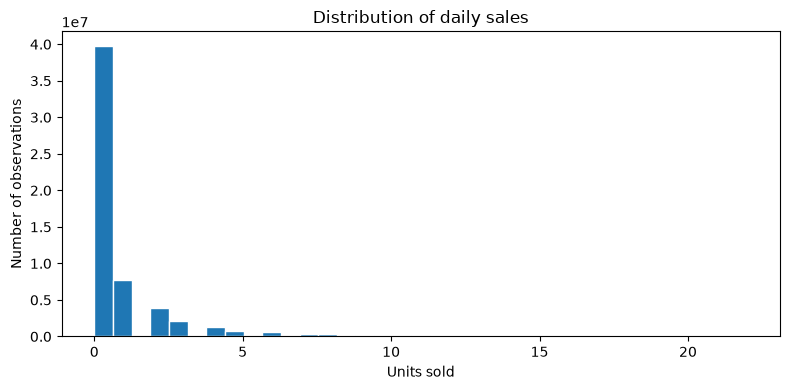

In [13]:
all_sales = daily_sales.to_numpy().ravel()
upper_limit = np.quantile(all_sales, 0.995)
sales_for_plot = all_sales[all_sales <= upper_limit]

plt.figure(figsize=(8, 4))
plt.hist(sales_for_plot, bins=35, edgecolor="white")
plt.title("Distribution of daily sales")
plt.xlabel("Units sold")
plt.ylabel("Number of observations")
plt.tight_layout()

plt.savefig(FIGURE_DIR / "demand_distribution.png", dpi=180)
plt.show()

## 14. What do zero sales mean?

A zero means no units were recorded as sold that day. It could mean there was no demand, or the item was unavailable. The dataset does not directly tell us which explanation applies, so we keep the recorded zeros without labelling them as stockouts.

## 15. Calculate total sales by date

We add sales across all product-store series to get total daily sales. This chart is for understanding overall patterns; the forecasting models will still be evaluated on individual series.

In [14]:
day_to_date = calendar.set_index("d")["date"]

aggregate_daily = pd.Series(
    daily_sales.sum(axis=0).to_numpy(),
    index=pd.DatetimeIndex(day_to_date.loc[sales_cols]),
    name="total_sales"
)

display(aggregate_daily.head())

date
2011-01-29    32631
2011-01-30    31749
2011-01-31    23783
2011-02-01    25412
2011-02-02    19146
Name: total_sales, dtype: int64

## 16. Group daily sales into weeks and months

Resampling adds the daily totals within each calendar week or month. This helps us see broader changes over time.

In [15]:
weekly_sales = aggregate_daily.resample("W").sum()
monthly_sales = aggregate_daily.resample("ME").sum()

print("Weekly totals:", len(weekly_sales))
print("Monthly totals:", len(monthly_sales))

Weekly totals: 274
Monthly totals: 64


## 17. Plot daily, weekly, and monthly sales

The daily chart shows the last 180 days for readability. The weekly and monthly charts show the broader pattern across the available sales history.

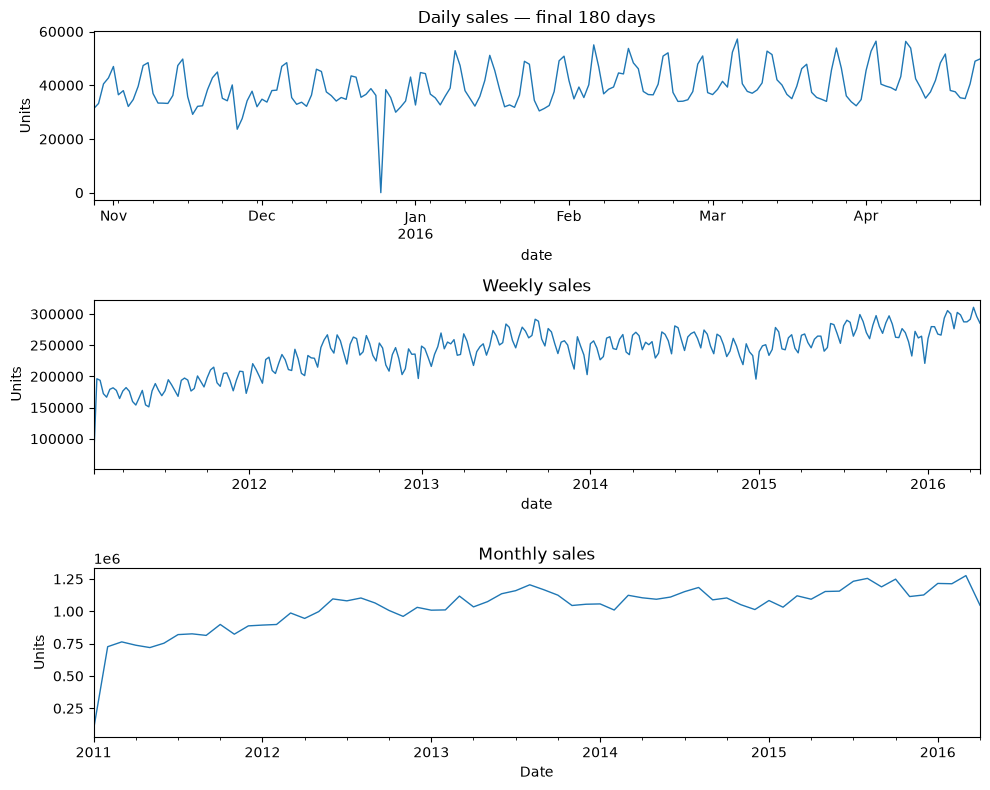

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8))

aggregate_daily.tail(180).plot(ax=axes[0], linewidth=1)
axes[0].set_title("Daily sales — final 180 days")
axes[0].set_ylabel("Units")

weekly_sales.plot(ax=axes[1], linewidth=1)
axes[1].set_title("Weekly sales")
axes[1].set_ylabel("Units")

monthly_sales.plot(ax=axes[2], linewidth=1)
axes[2].set_title("Monthly sales")
axes[2].set_ylabel("Units")
axes[2].set_xlabel("Date")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "aggregate_time_patterns.png", dpi=180)
plt.show()

## 18. Compare sales across weekdays

We calculate average total sales for each weekday. This helps us see whether some days tend to have higher overall sales than others.

In [17]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_average = (
    aggregate_daily.groupby(aggregate_daily.index.day_name())
    .mean()
    .reindex(weekday_order)
)

display(weekday_average.to_frame("average total units").round(1))

,average total units
date,
Monday,32853.0
Tuesday,30368.8
Wednesday,30010.0
Thursday,30205.0
Friday,34226.0
Saturday,41546.9
Sunday,41130.0


## 19. Plot the weekday averages

The bar chart makes it easier to compare average sales across the seven weekdays.

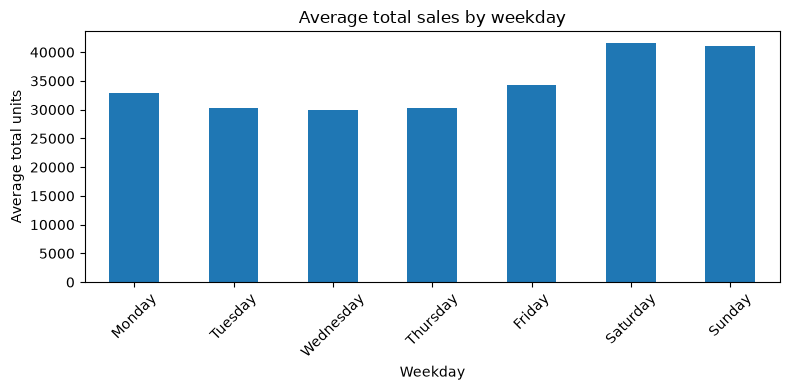

In [18]:
weekday_average.plot(kind="bar", figsize=(8, 4))
plt.title("Average total sales by weekday")
plt.xlabel("Weekday")
plt.ylabel("Average total units")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "weekday_average_sales.png", dpi=180)
plt.show()

## 20. Main findings

Use the outputs above to describe what the data shows:

- The sales file contains many product-store series and daily observations.
- A large share of daily observations are zero, so demand can be intermittent.
- Overall sales vary by date and weekday.
- Calendar event fields may be empty when no named event is recorded.
- The dataset does not identify stockouts directly, so zero sales should not automatically be treated as lost demand.

The plots describe the whole dataset. The next notebook selects a smaller, reproducible sample for model development.